# Oscillations and waves 5: Dispersion

*Learning path: oscillations and waves, part 5 of 7.* [Index](README.md) · Previous: [Sound and the Fourier transform](04-sound-and-fourier.ipynb) · Next: [Light as a wave](06-light-as-a-wave.ipynb)

Throw a stone into a pond and watch one ring of ripples closely. The little crests are born at the inner edge of the
ring, run outwards through it, and die at the outer edge. The ring as a whole moves at half the speed of its crests.
On the coast of California, surfers know that a storm near Antarctica announces itself days ahead: first a long, slow
swell with 20 seconds between waves, then, over the following day, shorter and shorter waves. Both are **dispersion**:
waves of different lengths travel at different speeds. Sound in air has almost none, which is why a band sounds
right from the back of a hall; water waves, light in glass and electrons in a crystal all have it.

**Who this is for.** You have done [lesson 4](04-sound-and-fourier.ipynb).

**What you will be able to do afterwards:**

1. describe a medium by its dispersion relation $\omega(k)$ and compute the phase velocity $\omega/k$;
2. derive the group velocity $d\omega/dk$ from two superposed waves;
3. build a wave packet and watch crests travel through it;
4. use the group velocity to predict when ocean swell arrives.

Plan about an hour and a half.

## 1. Dispersion relations

A wave $\cos(kx - \omega t)$ has **wavenumber** $k = 2\pi/\lambda$ and angular frequency $\omega$. Its crests move at
the **phase velocity** $v_p = \omega/k$. Every medium links $\omega$ to $k$ by a **dispersion relation**:

| medium | $\omega(k)$ | phase velocity |
|---|---|---|
| string, sound in air | $ck$ | $c$, the same for all wavelengths |
| chain of masses (lesson 2) | $2\omega_0\sin(ka/2)$ | falls for short waves |
| deep water | $\sqrt{gk}$ | $\sqrt{g/k}$: long waves are faster |
| shallow water, depth $h$ | $\sqrt{gh}\,k$ | $\sqrt{gh}$: no dispersion |

When $\omega$ is proportional to $k$, all waves move together and a shape keeps its form (lesson 3). Otherwise the
medium is **dispersive**: a shape made of many wavelengths comes apart. For deep water, the phase velocity of a
wave with $\lambda = 100$ m:

In [1]:
eval(convert(sqrt(const.g/(2*pi/(100 m))), km/h), 3)

45.0 km/h

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

45 km/h, while a 10 m ripple moves at about 14 km/h.

**Try this.** A tsunami has a wavelength of 200 km in an ocean 4 km deep, so it is a shallow-water wave. How fast does
it go?

## 2. Group velocity

Add two waves with slightly different $k$ and $\omega$:

$$\cos(k_1x - \omega_1t) + \cos(k_2x - \omega_2t) = 2\cos\left(\bar kx - \bar\omega t\right)
\cos\left(\tfrac{\Delta k}{2}x - \tfrac{\Delta\omega}{2}t\right).$$

The first factor is a wave moving at the phase velocity $\bar\omega/\bar k$. The second is an **envelope** (the beats
of lesson 4, now in space) moving at $\Delta\omega/\Delta k$. As the two waves get closer, that becomes the **group
velocity**

$$v_g = \frac{d\omega}{dk}.$$

Energy and information travel with the envelope, at $v_g$. For deep water:

In [2]:
w = sqrt(g*k);
simplify(diff(w, k)/(w/k))

1/2

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

The group velocity is exactly half the phase velocity: the pond's ring moves at half the speed of its crests. For the
chain of masses, $v_g = \omega_0 a\cos(ka/2)$ falls to zero at the shortest wavelength $\lambda = 2a$: that wave is a
standing pattern, carrying no energy anywhere.

**Try this.** Capillary ripples (a few millimetres long) obey $\omega^2 = (\sigma/\rho)k^3$. Find $v_g/v_p$.

## 3. A wave packet

A packet is a short burst of waves: many wavenumbers near $k_0$, with amplitudes falling off on both sides. Build one
from 21 deep-water waves (with $g = 1$) around $k_0 = 4$:

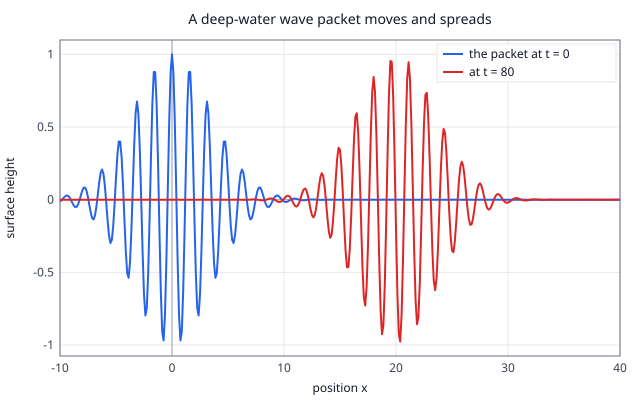

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
u = 0;
for j in -10:10
  kk = 4 + j/10;
  u = u + exp(-(j/4)^2)*cos(kk*x - sqrt(kk)*t);
end
u = u/sum(exp(-((-10:10)/4).^2));
p = plot(subs(u, t, 0), x, -10, 40);
p = show(p, plot(subs(u, t, 80), x, -10, 40));
p = legend(p, "the packet at t = 0", "at t = 80");
labels(title(p, "A deep-water wave packet moves and spreads"), "position x", "surface height")

In 80 time units the packet moved about 20, at $v_g = \tfrac12\sqrt{g/k_0} = 0.25$, and spread a little: its long waves
ran ahead and its short ones fell behind, so it is wider and lower. The crests inside move twice as fast. Play it to see crests appear at the
back, run forward through the packet, and vanish at the front:

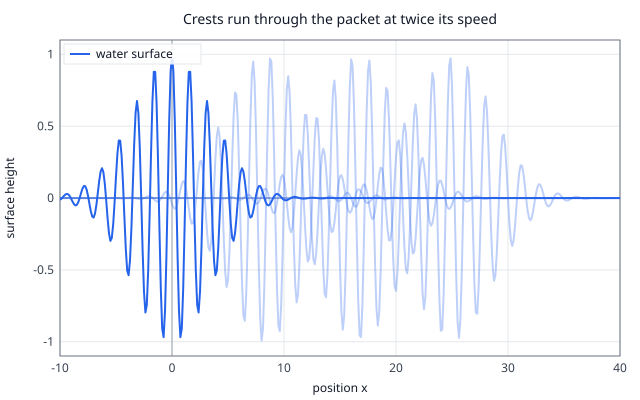

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
p = animate(u, x, -10, 40, t, 0, 100, 40);
p = legend(p, "water surface");
labels(title(p, "Crests run through the packet at twice its speed"), "position x", "surface height")

**Try this.** In the table of section 1, which medium would let the packet travel without spreading?

## 4. Swell from a distant storm

A storm far out at sea stirs up waves of all periods $T$. With $\omega = 2\pi/T$, deep water gives
$v_g = g/(2\omega) = gT/4\pi$: the long-period waves travel fastest. For a storm 3000 km away, the arrival times in
hours for 20 s and 14 s swell:

In [5]:
eval(3000000/(9.81*20/(4*pi))/3600, 3)
eval(3000000/(9.81*14/(4*pi))/3600, 3)

53.4

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

76.2

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

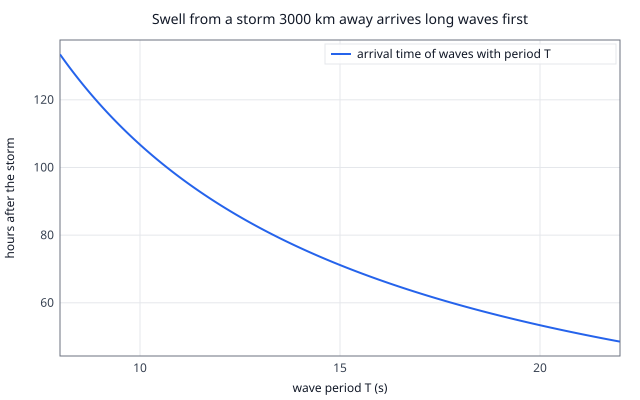

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
p = plot(4*pi*3000000/(9.81*T)/3600, T, 8, 22);
p = legend(p, "arrival time of waves with period T");
labels(title(p, "Swell from a storm 3000 km away arrives long waves first"), "wave period T (s)", "hours after the storm")

The long swell arrives more than a day before the short waves. In 1963 Walter Munk and colleagues turned this around:
from how the period of the arriving swell fell day by day, they worked out how far away its storm had been, and
traced swell arriving in California, Hawaii and even Alaska to storms in the Southern Ocean, more than 10 000 km
away.

**Try this.** If the period of the arriving swell falls from 18 s to 16 s in 12 hours, how far away was the storm?
(Arrival time $t = 4\pi d/(gT)$.)

## Summary

* A medium's dispersion relation $\omega(k)$ gives the phase velocity $\omega/k$ (crests) and the group velocity
  $d\omega/dk$ (envelopes, energy).
* Without dispersion ($\omega \propto k$) shapes travel unchanged; with it, packets spread.
* Deep water: $v_g = \tfrac12v_p$, so crests run through a packet, and long swell outruns short waves.

Next: [light as a wave](06-light-as-a-wave.ipynb).

## Exercises

1. **Shallow water.** Show that for $\omega = \sqrt{gh}\,k$ the group and phase velocities are equal.
2. **Chain group velocity.** For $\omega = 2\sin(k/2)$, plot $v_p$ and $v_g$ for $0 < k < \pi$. Where do they differ
   most?
3. **Ripples and waves.** With both gravity and surface tension, $\omega^2 = gk + (\sigma/\rho)k^3$. For water,
   $\sigma/\rho = 7.3\cdot10^{-5}$ m³/s². Find the wavelength with the slowest phase velocity, and that speed.
4. **Packet speed.** Change $k_0$ in section 3 to 1. How fast does the packet go now?
5. **Light in glass.** For light in a medium with refractive index $n(\omega)$, $k = n\omega/c$. Show that
   $v_g = c/(n + \omega\,dn/d\omega)$.
6. **Storm distance.** In exercise form: derive $d = gt^2/(4\pi)\cdot|dT/dt|$ from $t = 4\pi d/(gT)$, and use it on
   the numbers of the section 4 Try this.

## Hints and answers

* **Section 1, Try this.** $\sqrt{9.81 \cdot 4000} \approx 198$ m/s, about 710 km/h, the speed of a jet.
* **Section 2, Try this.** $v_g/v_p = 3/2$: ripple packets move faster than their crests.
* **Section 3, Try this.** Shallow water, or a string: $\omega \propto k$.
* **Section 4, Try this.** $t_1 = 4\pi d/(18g)$ and $t_2 = 4\pi d/(16g)$ differ by 12 h $= 43\,200$ s, so
  $d = 43\,200\,g/(4\pi(1/16 - 1/18)) \approx 4.85\cdot10^6$ m, about 4900 km.
* **Exercise 1.** $d\omega/dk = \sqrt{gh} = \omega/k$.
* **Exercise 2.** $v_p = 2\sin(k/2)/k$ and $v_g = \cos(k/2)$; at $k = \pi$, $v_p = 2/\pi$ and $v_g = 0$.
* **Exercise 3.** Minimising $v_p^2 = g/k + (\sigma/\rho)k$ gives $k = \sqrt{g\rho/\sigma}$, $\lambda \approx 1.7$ cm,
  and $v_p \approx 23$ cm/s. No wind wave is slower.
* **Exercise 4.** $v_g = \tfrac12\sqrt{1/1} = 0.5$, twice as fast.
* **Exercise 5.** $dk/d\omega = (n + \omega\,dn/d\omega)/c$.
* **Exercise 6.** $dt/dT = -4\pi d/(gT^2)$; with $T = 17$ s and $dT/dt = -2/(12\cdot3600)$, $d \approx 4.9\cdot10^6$ m.

## Sources

1. Lord Rayleigh, "On progressive waves", *Proceedings of the London Mathematical Society* 9, 21–26 (1877): group
   velocity.
2. W. H. Munk, G. R. Miller, F. E. Snodgrass and N. F. Barber, "Directional recording of swell from distant storms",
   *Philosophical Transactions of the Royal Society A* 255, 505–584 (1963).
3. J. Lighthill, *Waves in Fluids*, Cambridge University Press (1978), chapter 3.
4. H. Georgi, *The Physics of Waves*, Prentice Hall (1993), chapter 13.